# Classification Models on UCI Student Performance Data

**Dataset:** UCI Student Performance (Portuguese course file `student-por.csv`)
**Models:** Logistic Regression, Decision Tree, KNN, Naive Bayes (Gaussian), SVM
**Metrics:** Accuracy, AUC, Precision, Recall, F1, MCC


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
PASS_MARK = 10
CSV_PATH = "student-por.csv"
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## Step 1 - Load the dataset and check the assignment limits
The assignment needs **at least 12 features** and **at least 500 instances**.

In [2]:
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"{CSV_PATH} not found. Download the UCI 'Student Performance' zip, "
        "extract student-por.csv and upload it next to this notebook.")

df_raw = pd.read_csv(CSV_PATH, sep=";")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
df_raw.info()
print()
print("Missing values:", int(df_raw.isna().sum().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

## Step 2 - Build the classification target
`G3` is the final grade (0-20). We convert it to **pass_fail** (1 if G3 >= 10, else 0).
`G1` and `G2` are earlier period grades that almost give away `G3`, so they are dropped
to keep the problem meaningful. The remaining 30 columns are the input features.

In [4]:
df = df_raw.copy()
df["pass_fail"] = (df["G3"] >= PASS_MARK).astype(int)
df = df.drop(columns=["G1", "G2", "G3"])

X = df.drop(columns=["pass_fail"])
y = df["pass_fail"]

n_features = X.shape[1]
n_instances = X.shape[0]
print("Number of features :", n_features, "(minimum required: 12)")
print("Number of instances:", n_instances, "(minimum required: 500)")
assert n_features >= 12, "Dataset has fewer than 12 features"
assert n_instances >= 500, "Dataset has fewer than 500 instances"

print("\nClass distribution:")
print(y.value_counts().rename({0: "fail (0)", 1: "pass (1)"}))

Number of features : 30 (minimum required: 12)
Number of instances: 649 (minimum required: 500)

Class distribution:
pass_fail
pass (1)    549
fail (0)    100
Name: count, dtype: int64


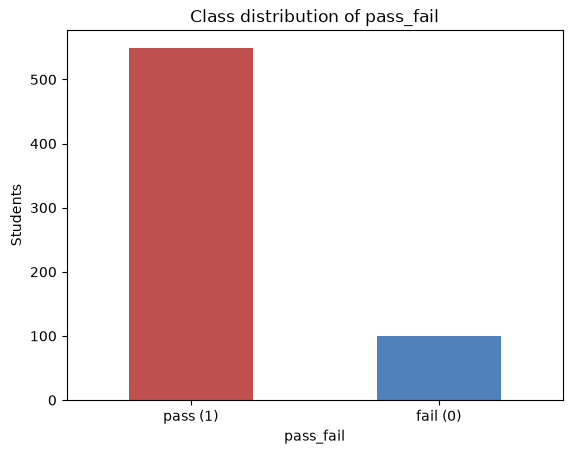

In [5]:
y.value_counts().rename({0: "fail (0)", 1: "pass (1)"}).plot(kind="bar", color=["#c0504d", "#4f81bd"])
plt.title("Class distribution of pass_fail")
plt.ylabel("Students")
plt.xticks(rotation=0)
plt.show()

## Step 3 - Train/test split and save `test_data.csv`

In [6]:
cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in X.columns if c not in cat_cols]
print("Categorical columns:", len(cat_cols), "| Numeric columns:", len(num_cols))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Test file for the Streamlit app: all input features + the target column
test_df = X_test.copy()
test_df["pass_fail"] = y_test.values
test_df.to_csv("test_data.csv", index=False)
print("Saved test_data.csv with columns:", test_df.shape[1])

Categorical columns: 17 | Numeric columns: 13
Train: (519, 30)  Test: (130, 30)
Saved test_data.csv with columns: 31


## Step 4 - Define the five models
Each model is a pipeline: one-hot encoding for categorical columns, scaling for numeric columns,
then the classifier. Saving the whole pipeline means the Streamlit app can load a model and predict
on the uploaded test CSV without any retraining.

In [7]:
def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
}
list(models.keys())

['Logistic Regression',
 'Decision Tree',
 'KNN',
 'Naive Bayes',
 'Support Vector Machine']

## Step 5 - Train, evaluate (6 metrics) and save every model

In [8]:
os.makedirs("model", exist_ok=True)

rows = []
trained = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    rows.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
    })
    trained[name] = pipe

    fname = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipe, os.path.join("model", fname))

results = pd.DataFrame(rows).round(4)
results.to_csv("metrics_comparison.csv", index=False)
results

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7923,0.6227,0.8673,0.8909,0.8789,0.1508
1,Decision Tree,0.7692,0.6057,0.8509,0.8818,0.8661,0.0349
2,KNN,0.8154,0.5845,0.8525,0.9455,0.8966,0.0682
3,Naive Bayes,0.6308,0.4950,0.8690,0.6636,0.7526,0.0857
4,Support Vector Machine,0.8308,0.6691,0.8607,0.9545,0.9052,0.1570


In [9]:
print("Saved model files:", sorted(os.listdir("model")))
assert len(os.listdir("model")) == 5, "Expected 5 saved models"

Saved model files: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'support_vector_machine.joblib']


## Step 6 - Confusion matrices on the test data

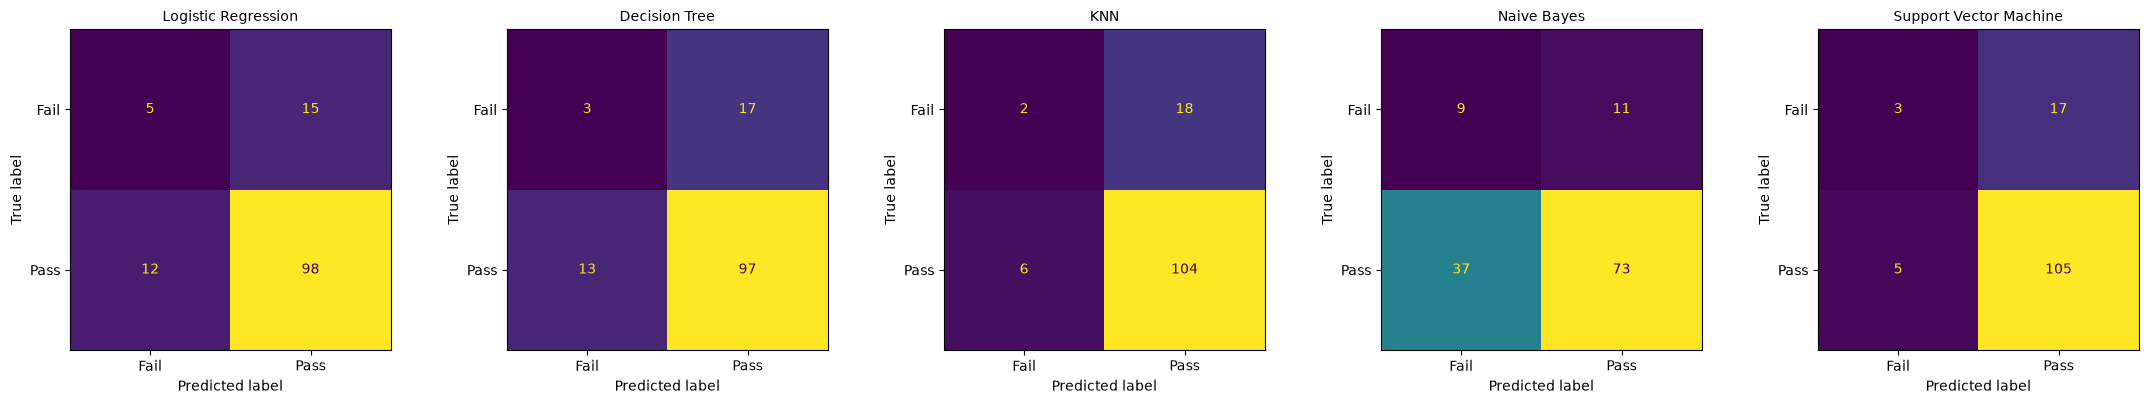

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, pipe) in zip(axes, trained.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Fail", "Pass"]).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

## Step 7 - Comparison table for the README (copy this into README.md)

In [11]:
def to_markdown_table(frame):
    cols = list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |",
             "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in frame.iterrows():
        lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

print(to_markdown_table(results))
best = results.sort_values(["MCC", "AUC"], ascending=False).iloc[0]
print("\nHighest MCC / AUC:", best["ML Model Name"])

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.7923 | 0.6227 | 0.8673 | 0.8909 | 0.8789 | 0.1508 |
| Decision Tree | 0.7692 | 0.6057 | 0.8509 | 0.8818 | 0.8661 | 0.0349 |
| KNN | 0.8154 | 0.5845 | 0.8525 | 0.9455 | 0.8966 | 0.0682 |
| Naive Bayes | 0.6308 | 0.495 | 0.869 | 0.6636 | 0.7526 | 0.0857 |
| Support Vector Machine | 0.8308 | 0.6691 | 0.8607 | 0.9545 | 0.9052 | 0.157 |

Highest MCC / AUC: Support Vector Machine


## Step 8 - Create `requirements.txt` for Streamlit Community Cloud

In [12]:
with open("requirements.txt", "w") as f:
    f.write("streamlit\nscikit-learn\nnumpy\npandas\nmatplotlib\nseaborn\njoblib\n")
print(open("requirements.txt").read())

streamlit
scikit-learn
numpy
pandas
matplotlib
seaborn
joblib



## Step 9 - Final file check (assignment Step 3 repository layout)
Everything below must be pushed to your GitHub repository, together with `app.py` and `README.md`.

In [13]:
required = ["test_data.csv", "requirements.txt", "metrics_comparison.csv"]
for f in required:
    print(("OK      " if os.path.exists(f) else "MISSING ") + f)
print("OK      model/ -> " + ", ".join(sorted(os.listdir("model"))))

OK      test_data.csv
OK      requirements.txt
OK      metrics_comparison.csv
OK      model/ -> decision_tree.joblib, knn.joblib, logistic_regression.joblib, naive_bayes.joblib, support_vector_machine.joblib
